In [40]:
import datetime

from rocketpy import Environment, Flight, Function, Rocket
from rocketpy import SolidMotor

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:


env_era5 = Environment(
    date=(2026, 3, 29, 14),
    latitude=42.70446,
    longitude=-77.19169,
    elevation=1383.4,
)

filename = "Rocketpy Files/urrg_weather.nc"

env_era5.set_atmospheric_model(
    type="Reanalysis",
    file=filename,
    dictionary="ECMWF",
)

env_era5.plots.atmospheric_model()

Nozzle Details
Nozzle Radius: 0.0195195057 m
Nozzle Throat Radius: 0.0108946078 m

Grain Details
Number of Grains: 3
Grain Spacing: 0 m
Grain Density: 1765.65619 kg/m3
Grain Outer Radius: 0.0422166054 m
Grain Inner Radius: 0.0136182598 m
Grain Height: 0.153432394 m
Grain Volume: 0.001 m3
Grain Mass: 1.359 kg

Motor Details
Total Burning Time: 7.1 s
Total Propellant Mass: 4.077 kg
Structural Mass Ratio: 0.410
Average Propellant Exhaust Velocity: 1878.844 m/s
Average Thrust: 1078.880 N
Maximum Thrust: 1513.113 N at 2.644 s after ignition.
Total Impulse: 7660.047 Ns



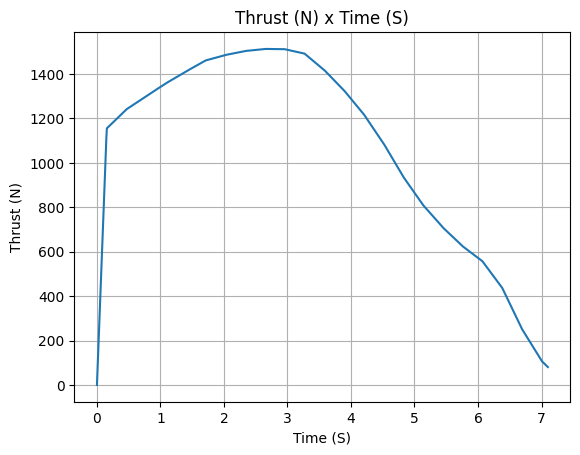

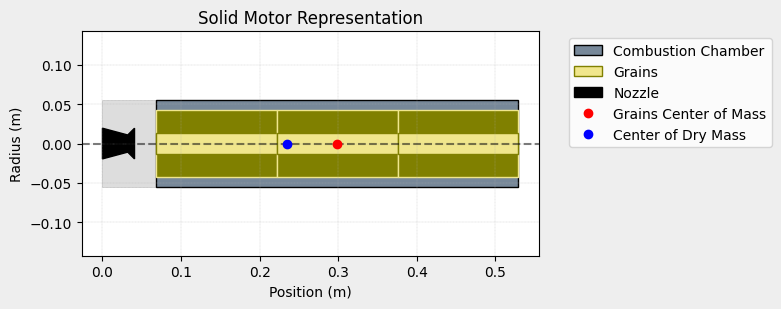

In [42]:
m1419AeroTech = SolidMotor(
  thrust_source="Rocketpy Files/AeroTech_M1419W.eng",
  dry_mass=2.839,
  dry_inertia = (0.0966, 0.0966, 0.00377),
  nozzle_radius=0.0195195057,
  grain_number=3,
  grain_density=1765.65619,
  grain_outer_radius=0.0422166054,
  grain_initial_inner_radius=0.0136182598,
  grain_initial_height=0.153432394,
  grain_separation=0,
  grains_center_of_mass_position=0.298693832 ,
  center_of_dry_mass_position=0.234442 ,
  nozzle_position=0 ,
  burn_time=7.1,
  throat_radius=0.0108946078,
  coordinate_system_orientation="nozzle_to_combustion_chamber",
)

m1419AeroTech.info()
m1419AeroTech.draw()

In [43]:
argusTest = Rocket(
    radius=0.0655  ,
    mass=16.040,
    inertia=(8.41, 8.41, 0.0549),
    power_off_drag="Rocketpy Files/cd_power_off.csv",
    power_on_drag="Rocketpy Files/cd_power_on.csv",
    center_of_mass_without_motor=1.4,
    coordinate_system_orientation="tail_to_nose",
)

In [44]:
argusTest.add_motor(m1419AeroTech, position=0 )

In [45]:
nose_cone = argusTest.add_nose(
    length=0.508, kind="ogive", position=2.63
)

fin_set = argusTest.add_trapezoidal_fins(
    n=4,
    root_chord=0.318,
    tip_chord=0.122,
    span=0.122,
    position=0.318,
    cant_angle=0,
)
tail = argusTest.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.001, position=0
)

In [46]:
rail_buttons = argusTest.set_rail_buttons(
    upper_button_position=1.13,
    lower_button_position=0.0127,
    angular_position=45,
)

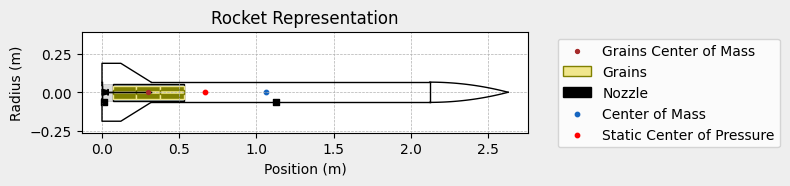

In [47]:
argusTest.draw()

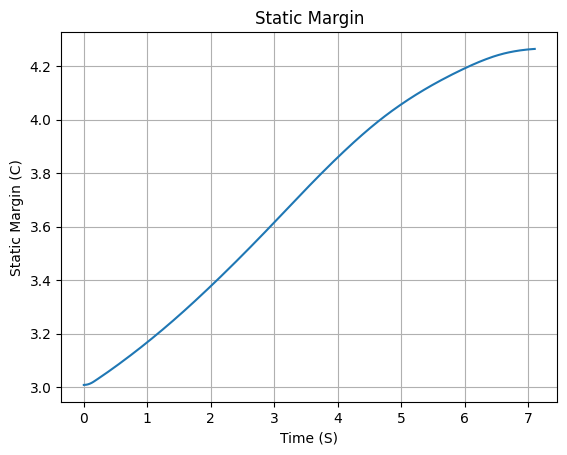

In [48]:
argusTest.plots.static_margin()


Inertia Details

Rocket Mass: 16.040 kg (without motor)
Rocket Dry Mass: 18.879 kg (with unloaded motor)
Rocket Loaded Mass: 22.956 kg
Rocket Structural Mass Ratio: 0.822
Rocket Inertia (with unloaded motor) 11: 11.783 kg*m2
Rocket Inertia (with unloaded motor) 22: 11.783 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.059 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0655 m
Rocket Frontal Area: 0.013478 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.175 m
Rocket Center of Dry Mass - Nozzle Exit: 1.225 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.926 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.164 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 8.407/rad
Tail Lift Coefficient 

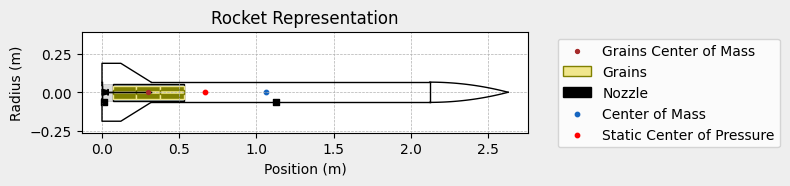


Mass Plots
----------------------------------------


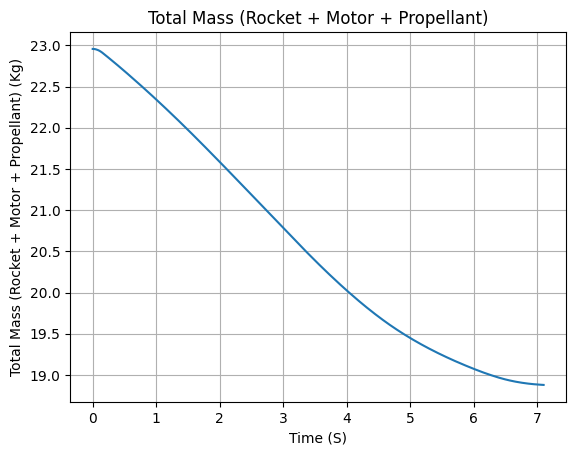

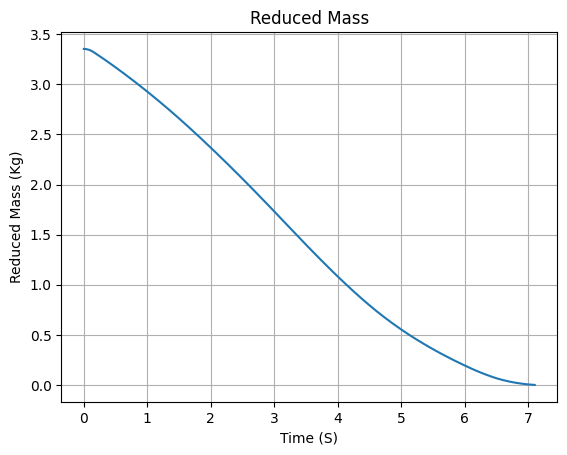


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


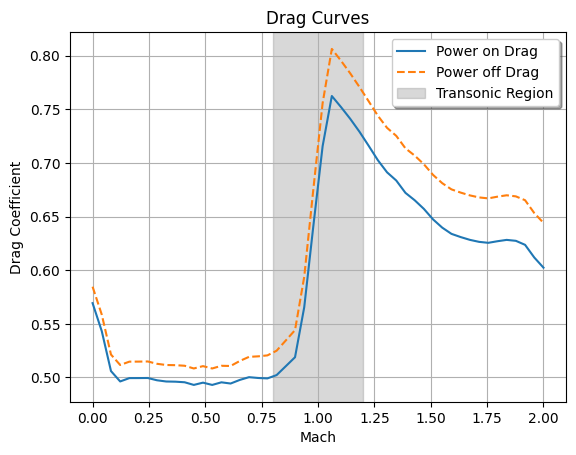


Stability Plots
--------------------


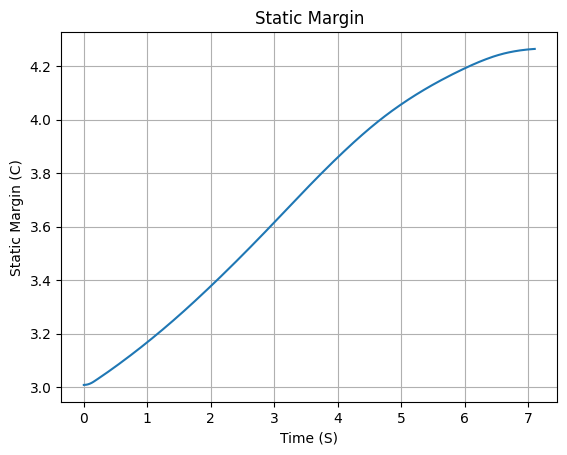

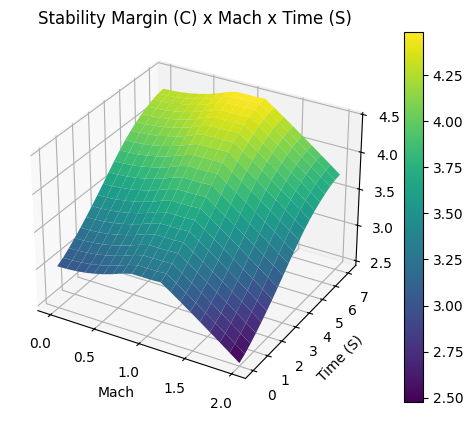


Thrust-to-Weight Plot
----------------------------------------


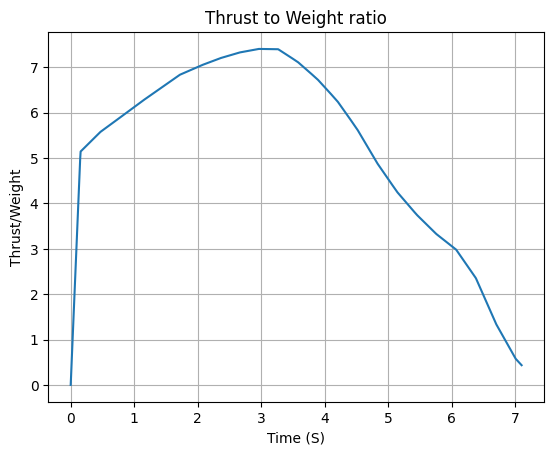

In [49]:
argusTest.all_info()

In [50]:
flight_custom = Flight(
    rocket=argusTest,
    environment=env_era5,
    rail_length=6.09600   ,
    inclination=85,          # Rail inclination angle (degrees from horizontal)
    heading=90,              # Launch direction (degrees from North)
)


Apogee State

Apogee Time: 26.066 s
Apogee Altitude: 4509.663 m (ASL) | 3126.263 m (AGL)
Apogee Freestream Speed: 66.224 m/s
Apogee X position: -1130.072 m
Apogee Y position: 182.502 m
Apogee latitude: 42.7061011°
Apogee longitude: -77.2055259°


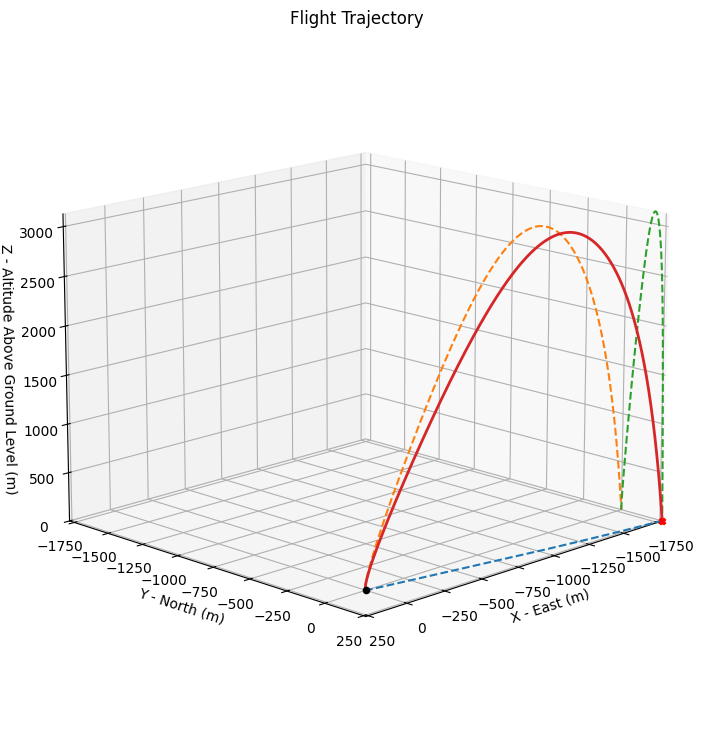

In [51]:
flight_custom.prints.apogee_conditions()
flight_custom.plots.trajectory_3d()


In [39]:
from rocketpy.simulation.flight_data_exporter import FlightDataExporter

exporter = FlightDataExporter(flight_custom)

exporter.export_kml(
    file_name="trajectory.kml",
    extrude=True,
    altitude_mode="absolute"
)

File  trajectory.kml  saved with success!
